# Um estudo computacional dos harmônicos esféricos

- Pet-Física UFRN
- Petiana: Juliana Magalhães Gonçalves
- Data: 16 de novembro de 2026.

$\quad$ Serão abordados neste `Notebook` os harmônicos esféricos, os quais correspondem à solução da parte angular da equação de Laplace em coordenadas esféricas e são ferramentas essenciais para a resolução de diversos problemas físicos. Aqui, visualizaremos graficamente os harmônicos esféricos e seu comportamento sob diferentes escolhas de parâmetros de suas funções, bem como o comportamento deles quando aplicados diretamente à equação de Laplace.

$\quad$ Assim, este `Notebook` está organizado da seguinte maneira:

1. *A equação de Laplace em coordenadas esféricas;*
2. *Implementando os harmônicos esféricos;*
3. *Visualização em 3D*
4. *Conclusão.*

## Pré-requisitos

$\quad$A leitura e a compreensão deste `Notebook` requerem conhecimento prévio em cálculo diferencial, cálculo vetorial e coordenadas curvilíneas. É também preferível que a leitora ou o leitor possua um pouco de falimiaridade com a equação de Laplace. Para um estudo dessa equação em coordenadas cartesianas e polares, indico a leitura do `Notebook` *Equação de Laplace* (2025).

$\quad$Vale salientar, ainda, que utilizaremos aqui a implementação dos harmônicos esféricos já disponíveis na biblioteca `SciPy`.

### Importando bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from mpl_toolkits.mplot3d import Axes3D
from scipy.special import sph_harm_y

### Detalhes das bibliotecas

In [2]:
%load_ext version_information
%version_information numpy, matplotlib, scipy

Software versions
Python 3.13.3 64bit [GCC 14.2.0]
IPython 9.12.0
OS Linux 6.14.0 37 generic x86_64 with glibc2.41
numpy 2.4.3
matplotlib 3.10.9
scipy 1.17.1
Sun Nov 15 22:13:01 2026 -03

## 1. A equação de Laplace em coordenadas esféricas

$\quad$De modo geral, a equação de Laplace descreve situações nas quais uma grandeza física apresenta uma distribuição espacial em equilíbrio, sem fontes ou sumidouros no interior da região considerada. Algumas aplicações dessa poderosa equação para a física incluem o potencial elétrico em uma região livre de cargas, o potencial gravitacional em regiões externas à distribuição de matéria e o estudo do comportamento de fluidos em escoamentos ideais.

$\quad$Para um campo escalar $f$, a equação de Laplace é dada por

$$
\begin{equation}
\nabla^2f=0,\tag{1}
\end{equation}
$$

onde $\nabla^2$ é o Laplaciano.

$\quad$Nas coordenadas esféricas $(r,\theta,\phi)$ tais que

$$
r=\sqrt{x^2+y^2+z^2},
$$

$$
\theta=\cos^{-1}(\frac{z}{r}),
$$

$$
\begin{equation}
\phi=\tan^{-1}(\frac{y}{x}),\tag{2}
\end{equation}
$$

o laplaciano do campo escalar $f$ é dado por

$$
\begin{equation}
\nabla^2f=\frac{1}{r^2}\frac{\partial}{\partial r}(r^2\frac{\partial f}{\partial r})+\frac{1}{r^2\sin\theta}\frac{\partial}{\partial\theta}(\sin\theta\frac{\partial f}{\partial\theta})+\frac{1}{r^2\sin^2\theta}\frac{\partial^2f}{\partial\phi^2}.\tag{3}
\end{equation}
$$

Substituindo-o na equação (1), tem-se

$$
\begin{equation}
\frac{1}{r^2}\frac{\partial}{\partial r}(r^2\frac{\partial f}{\partial r})+\frac{1}{r^2\sin\theta}\frac{\partial}{\partial\theta}(\sin\theta\frac{\partial f}{\partial\theta})+\frac{1}{r^2\sin^2\theta}\frac{\partial^2f}{\partial\phi^2}=0.\tag{4}
\end{equation}
$$

$\quad$Essa é a equação de Laplace em coordenadas esféricas. A seguir, vejamos sua resolução por separação de variáveis e, a partir dela, a obtenção dos harmônicos esféricos.

### 1.1. Resolução por separação de variáveis e definição analítica dos harmônicos esféricos

$\quad$Resolver a equação de Laplace por separação de variáveis consiste em assumir funções separadas para cada coordenada, ou seja, assumir que ela admite uma solução na forma

$$
\begin{equation}
f(r,\theta,\phi)=R(r)\Theta(\theta)\Phi(\phi)\tag{5}
\end{equation}
$$

e, em seguida, substituir essa solução suposta na própria equação $(4)$. Eis o cálculo das derivadas parciais da solução assumida.

$$
\frac{\partial f}{\partial r}=\Theta\Phi\frac{dR}{dr},
$$

$$
\frac{\partial f}{\partial\theta}=R\Phi\frac{d\Theta}{d\theta},
$$

$$
\begin{equation}
\frac{\partial^2f}{\partial\phi^2}=R\Theta\frac{d^2\Phi}{d\phi^2}.\tag{6}
\end{equation}
$$

$\quad$Substituindo-as em $(4)$, obtém-se

$$
\begin{equation}
\frac{\Theta\Phi}{r^2}\frac{d}{dr}(r^2\frac{dR}{dr})+\frac{R\Phi}{r^2\sin\theta}\frac{d}{d\theta}(\sin\theta\frac{d\Theta}{d\theta})+\frac{R\Theta}{r^2\sin^2\theta}\frac{d^2\Phi}{d\phi^2}=0.\tag{7}
\end{equation}
$$

Simplificando,

$$
\begin{equation}
\frac{1}{R}\frac{d}{dr}(r^2\frac{dR}{dr})+\frac{1}{\Theta\sin\theta}\frac{d}{d\theta}(\sin\theta\frac{d\Theta}{d\theta})+\frac{1}{\Phi\sin^2\theta}\frac{d^2\Phi}{d\phi^2}=0.\tag{8}
\end{equation}
$$

$\quad$Com isso, é possível separar a nossa equação em duas partes: uma radial e uma angular. Como o lado direito dela é igual a zero, a parte angular e a parte radial devem ser constantes de mesmo módulo e de sinais opostos. Definindo a constante de separação $\frac{1}{R}\frac{d}{dr}(r^2\frac{dR}{dr})\equiv\lambda$, temos que

$$
\begin{equation}
\frac{1}{\Theta\sin\theta}\frac{d}{d\theta}(\sin\theta\frac{d\Theta}{d\theta})+\frac{1}{\Phi\sin^2\theta}\frac{d^2\Phi}{d\phi^2}+\lambda=0.\tag{9}
\end{equation}
$$

Separando os termos que dependem de $\phi$ dos que dependem de $\theta$,

$$
\begin{equation}
\frac{1}{\Phi}\frac{d^2\Phi}{d\phi^2}=-\sin^2\theta[\frac{1}{\Theta}\frac{1}{\sin\theta}\frac{d}{d\theta}(\sin\theta\frac{d\Theta}{d\theta})+\lambda]\equiv-m^2.\tag{10}
\end{equation}
$$

Logo,

$$
\begin{equation}
\frac{d^2\Phi}{d\phi^2}+m^2\Phi=0.\tag{11}
\end{equation}
$$

$\quad$A equação $(11)$ é uma equação diferencial ordinária homogênea, a qual admite solução geral na forma

$$
\begin{equation}
\Phi(\phi)=Ae^{im\phi}+Be^{-im\phi}.\tag{12}
\end{equation}
$$

$\quad$A fim de respeitar a periodicidade de $\Phi$ em $2\pi$, ou seja, $\Phi(\phi+2\pi)=\Phi(\phi)$, é exigido que seja estabelecida a condição de que $m\in\mathbb{Z}$. Logo, a equação $(12)$ pode ser reescrita como

$$
\begin{equation}
\Phi(\phi)=Ce^{im\phi}.\tag{13}
\end{equation}
$$

$\quad$Substituindo a constante de separação, a equação para $\Theta$ fica

$$
\begin{equation}
\frac{1}{\sin\theta}\frac{d}{d\theta}(\sin\theta\frac{d\Theta}{d\theta})+(\lambda-\frac{m^2}{\sin^2\theta})\Theta=0.\tag{14}
\end{equation}
$$

$\quad$Note que a equação $(14)$ é uma equação diferencial associada de Legendre, de modo que a solução angular regular nos polos da esfera ($\theta=0$ e $\theta=\pi$) exige que $\lambda$ não assuma qualquer valor. Com efeito, as soluções regulares aparecem quando $\lambda=\ell(\ell+1)$, em que $\ell=0,1,2,3,...$ e $|m|\leq\ell$. Logo,

$$
\begin{equation}
\frac{1}{\sin\theta}\frac{d}{d\theta}(\sin\theta\frac{d\Theta}{d\theta})+[\ell(\ell+1)-\frac{m^2}{\sin^2\theta}]\Theta=0.\tag{15}
\end{equation}
$$

$\quad$Fazendo-se a mudança de variável $x=\cos\theta$, a equação anterior se torna

$$
\begin{equation}
(1-x^2)\frac{d^2\Theta}{dx^2}-2x\frac{d\Theta}{dx}+[\ell(\ell+1)-\frac{m^2}{1-x^2}]\Theta=0,\tag{16}
\end{equation}
$$

a qual é a exata equação diferencial associada de Legendre. Sua solução regular nos polos da esfera em $\theta=0$ e $\theta=\pi$, ou seja, $x=-1$ e $x=1$, é dada pelos polinômios associados de Legendre

$$
\begin{equation}
\Theta(x)=CP_\ell^m(x),\tag{17}
\end{equation}
$$

ou

$$
\begin{equation}
\Theta(\theta)=CP_\ell^m(\cos\theta).\tag{18}
\end{equation}
$$

$\quad$Com as soluções gerais das partes angulares azimutal e polar obtidas respectivamente nas equações $(13)$ e $(18)$, é possível definir a solução completa da parte angular da equação de Laplace, e os harmônicos esféricos podem, enfim, ser construídos. Como tal solução é o produto das duas funções,

$$
\begin{equation}
Y_\ell^m(\theta,\phi)=N_{\ell m}P_\ell^m(\cos\theta)e^{im\phi},\tag{19}
\end{equation}
$$

em que $N_{\ell m}$ é a constante de normalização obtida a partir da condição

$$
\begin{equation}
\int_{0}^{2\pi}\int_{0}^{\pi}|Y_\ell^m(\theta,\phi)|^2\sin\theta d\theta d\phi=1.\tag{20}
\end{equation}
$$

$$
\begin{equation}
|N_{\ell m}|^2\int_{0}^{2\pi}|e^{im\phi}|^2d\phi\int_{0}^{\pi}|P_\ell^m(\cos\theta)|^2\sin\theta d\theta=1.
\end{equation}
$$

$$
\begin{equation}
|N_{\ell m}|^2(2\pi)\frac{2(\ell+m)!}{(2\ell+1)(\ell-m)!}=1.\tag{21}
\end{equation}
$$

$\quad$Assumindo a constante real positiva, obtemos

$$
\begin{equation}
N_{\ell m}=\sqrt{\frac{2\ell+1}{4\pi}\frac{(\ell-m)!}{(\ell+m)!}}.\tag{22}
\end{equation}
$$

## 2. Implementando os harmônicos esféricos

$\quad$Como já foi mencionado, utilizaremos os harmônicos esféricos disponíveis na biblioteca `SciPy`. Este primeiro bloco é responsável por "preparar o terreno matemático" e calcular os valores da função. Os harmônicos esféricos são funções que dependem de dois ângulos ($\theta$  e  $\phi$), então precisamos criar uma grade com todas as combinações possíveis desses ângulos.

In [3]:
l = 5
m = 4

theta = np.linspace(0, np.pi, 200)
phi = np.linspace(0, 2*np.pi, 200)

Theta, Phi = np.meshgrid(theta, phi)

Y = sph_harm_y(l, m, Theta, Phi)

print(Y.shape)

(200, 200)


Aqui, foi obtida uma matriz de números complexos que contém os valores de $Y_5^4(\theta,\phi)$. Adotei $\ell=5$ e $m=4$, porém é interessante variar os valores de $\ell$ e de $m$ a fim de ver o que será abordado a seguir para diferentes harmônicos e "brincar" com as diferenças de formatos dos harmônicos a depender dos valores escolhidos.

$\quad$Vejamos, a seguir, uma visualização dos nós angulares, os quais se formam nas regiões em que o harmônico esférico se anula. Será como pegar a matriz bidimensional calculada e a projeta num plano, tal qual uma projeção retangular do globo terrestre. 

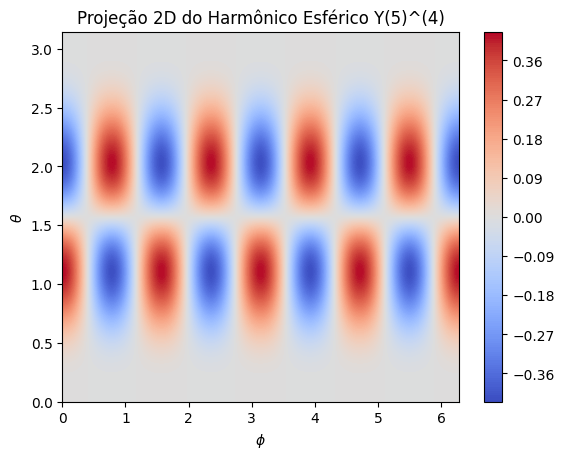

In [4]:
# Tomamos a parte real do harmônico para fins de visualização
Yvals = Y.real

fig, ax = plt.subplots()

contour = ax.contourf(
    Phi,
    Theta,
    Yvals,
    levels=200,
    cmap='coolwarm'
)

ax.set_xlabel(r'$\phi$')
ax.set_ylabel(r'$\theta$')
ax.set_title(f'Projeção 2D do Harmônico Esférico Y({l})^({m})')

plt.colorbar(contour, ax=ax)
plt.show()

A distribuição dos nós angulares depende simultaneamente dos valores de $\ell$ e $m$. O índice $\ell$ determina o grau do polinômio associado de Legendre, enquanto $m$ influencia tanto sua dependência polar quanto a variação azimutal. A visualização da parte real permite observar como esses parâmetros modificam a distribuição dos nós sobre a esfera.

## 3. Visualização em 3D

$\quad$Esta etapa é a mais visualmente interessante, pois plota o harmônico em 3D. Em vez de apenas pintar uma esfera perfeita com cores, o código "amassa" e "estica" o raio da esfera com base no valor da função, criando lóbulos. Aqui, tornam-se mais visíveis, por exemplo, os impactos visuais da escolha de diferentes valores de $m$.

Text(0.5, 0, 'Z')

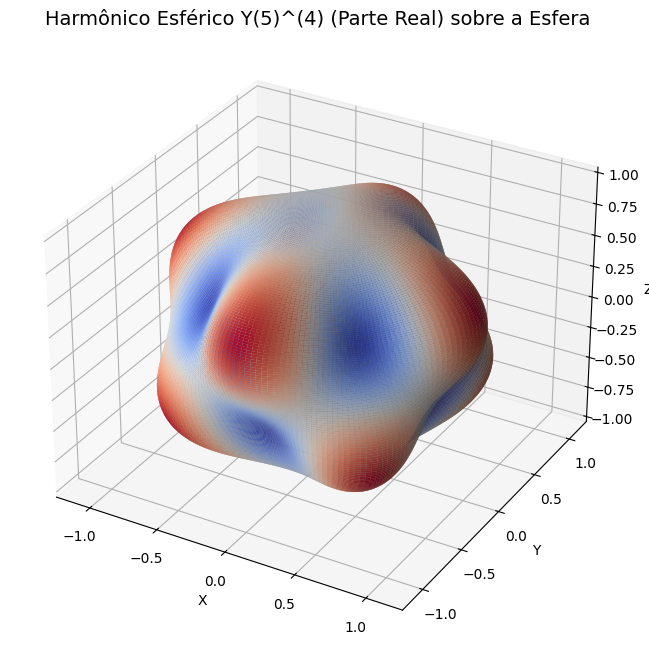

In [6]:
# Para ver os picos e vales na superfície esférica, definimos o raio como o raio de uma esfera unitária (1.0) somado ao valor do harmônico (multiplicado por um fator de escala para que a deformação fique evidente)
escala = 0.4
radii = 1.0 + escala*Yvals

# Mapeamento de cores baseado estritamente nos valores de Yvals (min ao max)
Ymax, Ymin = Yvals.max(), Yvals.min()
if Ymax != Ymin:
    Ycolors = (Yvals - Ymin) / (Ymax - Ymin)
else:
    Ycolors = np.ones(Yvals.shape) * 0.5

# Computa as coordenadas cartesianas deformadas pelo raio
x = radii * np.sin(Theta) * np.cos(Phi)
y = radii * np.sin(Theta) * np.sin(Phi)
z = radii * np.cos(Theta)

# Plotagem 3D
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Plotando a superfície deformada
surf = ax.plot_surface(x, y, z, rstride=1, cstride=1, facecolors=cm.coolwarm(Ycolors), edgecolor='none', alpha=0.95)

# Configurações de exibição e limites dos eixos
ax.set_title(f'Harmônico Esférico Y({l})^({m}) (Parte Real) sobre a Esfera', fontsize=14)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

## 4. Conclusão

$\quad$Neste `Notebook`, foi realizado um estudo analítico e computacional dos harmônicos esféricos, partindo da equação de Laplace em coordenadas esféricas e utilizando o método de separação de variáveis para obter sua solução angular. A partir desse procedimento, foi possível estabelecer a relação entre os polinômios associados de Legendre e os harmônicos esféricos, bem como compreender a origem de seus índices e suas respectivas condições de normalização. Na etapa computacional, as representações bidimensionais e tridimensionais permitiram observar a distribuição angular desses harmônicos, evidenciando a influência dos parâmetros escolhidos sobre sua estrutura e seus nós.

$\quad$Dessa forma, evidenciamos a importância dos harmônicos esféricos como ferramentas matemáticas para a descrição de fenômenos com dependência angular e para a resolução de equações diferenciais parciais em sistemas com geometria esférica.

## Referências

[1] Newman, Mark. 2013. *Computational Physics*. 1 ed.

[2] Arfken, George; Weber, Hans; Harris, Frank. 2013. *Mathematical Methods for Physicists*. 7 ed.

[3] GRIFFITHS, David J. *Introduction to Electrodynamics*. 4. ed. Boston: Pearson, 2013.

[4] HILL, Christian. E8.12: Visualizing the spherical harmonics. In: *Learning Scientific Programming with Python*. 2. ed. SciPython. Disponível em: https://scipython.com/books/book2/chapter-8-scipy/examples/visualizing-the-spherical-harmonics/.